# 80 km/h, retour aux 90 km/h : quel effet sur la mortalité routière ?

**Projet Python pour la data science — ENSAE 2A, 2026-2027**
Héloïse Gonon, Samir …, Brice … *(à compléter)*

> **À rédiger en dernier : résumé en 5 lignes** (question, données, méthode, résultat principal, principale limite).

## Comment exécuter ce notebook

1. Installer les dépendances : `pip install -r requirements.txt`.
2. Lancer toutes les cellules dans l'ordre (« Run All »).

Au premier lancement, les données sont téléchargées depuis leurs sources publiques (data.gouv.fr, INSEE, SDES, cartiflette) puis nettoyées : compter **XX minutes** *(à mesurer)*. Les fichiers produits sont gardés dans `data/processed/` (non versionné) et relus aux lancements suivants. Le code est dans `scripts/` ; ce notebook ne fait qu'appeler les fonctions et commenter les résultats.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("scripts").resolve()))

import data_analysis as da
import graphiques as gr
import indicateurs as ind
from collecte import charger_contours, charger_departements_90, charger_population, charger_radars

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
gr.appliquer_style()

# Variable principale pour Q2 : tués sur les routes départementales hors agglomération
VARIABLE_Q2 = "tues_rd"

## 1. Introduction

### 1.1 Contexte

> **À rédiger**

### 1.2 Question et hypothèses

**La baisse de la vitesse autorisée à 80 km/h a-t-elle réduit la mortalité routière, et le retour aux 90 km/h l'a-t-il fait remonter ?**

| Hypothèse | Ce qu'on devrait observer si elle est vraie |
|---|---|
| H1 : le 80 km/h a réduit la mortalité | Rupture à la baisse en 2018-2019 sur le réseau concerné, absente ou plus faible ailleurs |
| H2 : le retour aux 90 km/h a augmenté la mortalité | Après relèvement, évolution moins favorable dans les départements relevés que dans ceux restés à 80 |
| H3 : l'effet dépend de l'intensité | Écart plus grand pour les relèvements totaux que partiels |
| H4 : l'effet passe par certains types d'accidents | Variation concentrée sur les chocs frontaux et les sorties de route |

> ⚠️ Nous mesurons l'effet d'un **changement de règle**, pas d'un changement de vitesse observée : les vitesses pratiquées ne sont pas disponibles.

## 2. Données

### 2.1 Sources

| Source | Producteur | Accès dans le code | Rôle |
|---|---|---|---|
| Accidents corporels (BAAC) 2010-2024 | ONISR | API data.gouv.fr (`collecte.telecharger_baac`) | Tués, accidents |
| Départements revenus aux 90 km/h | **Construite par nous** | `data/departements_90.csv` (versionné) | Groupes traités / témoins |
| Population par département | INSEE | API Melodi (`charger_population`) | Taux par habitant |
| Ventes de carburants routiers | SDES | API DiDo (`charger_carburants`) | Indicateur du trafic (2020) |
| Radars fixes | Ministère de l'Intérieur | data.gouv.fr (`charger_radars`) | Q3 (annexe) |
| Contours des départements | IGN | `cartiflette` | Cartes |

In [2]:
accidents, panel = ind.charger_ou_construire()
groupes = ind.affecter_groupes(charger_departements_90())
population = charger_population()
contours = charger_contours()

print(f"{len(accidents):,} accidents de {accidents['annee'].min()} à {accidents['annee'].max()}")
print(f"Panel : {panel['code_dep'].nunique()} départements × {panel['date_mois'].nunique()} mois")

881,052 accidents de 2010 à 2024
Panel : 96 départements × 180 mois


### 2.2 La table des départements revenus aux 90 km/h

Aucune table officielle ne recense proprement les relèvements : nous l'avons construite à partir de l'étude ONISR de février 2024 (base officielle), de la liste L'Argus 2026, de la liste de la Ligue de défense des conducteurs et de la presse locale. La méthode complète et les points encore incertains sont dans `docs/collecte_departements.md`.

**Groupes utilisés.** `G90_total` : au moins 80 % du réseau départemental relevé ; `G90_partiel` : relèvement partiel ; `G80` : aucun relèvement avant fin 2024 (Morbihan et Eure, relevés en 2025-2026, sont donc dans `G80`).

In [3]:
display(groupes["groupe"].value_counts().rename("départements").to_frame())
display(
    groupes.loc[groupes["groupe"] != "G80", ["nom_dep", "groupe", "date_releve_eff", "precision_date", "part_releve"]]
    .sort_values("date_releve_eff")
    .head(10)
)

,départements
groupe,
G80,46
G90_partiel,42
G90_total,8


,nom_dep,groupe,date_releve_eff,precision_date,part_releve
52,Haute-Marne,G90_partiel,2020-01-09,jour,0.197
18,Corrèze,G90_total,2020-02-01,jour,0.989
14,Cantal,G90_total,2020-02-01,jour,1.000
19,Côte-d'Or,G90_partiel,2020-03-02,jour,0.204
67,Bas-Rhin,G90_partiel,2020-03-08,jour,0.016
77,Seine-et-Marne,G90_partiel,2020-03-09,jour,0.260
41,Loir-et-Cher,G90_partiel,2020-06-02,jour,0.096
61,Orne,G90_partiel,2020-06-12,jour,0.349
4,Hautes-Alpes,G90_partiel,2020-06-15,jour,0.160
43,Haute-Loire,G90_partiel,2020-06-30,jour,0.032


> **À rédiger.**

### 2.3 Nettoyage et harmonisation des BAAC

Traitements codés dans `scripts/clean_data.py` :

- **séparateur et encodage** détectés pour chaque fichier (ils changent selon les années) ;
- **codes département** des anciens fichiers ramenés au format officiel (`590` → `59`, `201` → `2A`) ;
- **coordonnées** d'avant 2019 converties (entiers divisés par 100 000) et valeurs aberrantes retirées ;
- **valeurs « non renseigné »** (`-1`) converties en valeurs manquantes ;
- usagers et véhicules **agrégés au niveau de l'accident**, puis fusion des quatre tables.

**Réseau concerné par le 80 km/h** : routes nationales ou départementales, hors agglomération, à double sens. Pour Q2, on se restreint aux **routes départementales** (`catr == 3`), les seules que les départements peuvent relever. Indicateur principal : les **tués à 30 jours** (les blessés hospitalisés ne sont plus fiables depuis 2018).

> **À compléter**

In [4]:
comparaison = ind.verifier_coherence_onisr(accidents, charger_departements_90())
display(comparaison[["tues_2019_calc", "tues_ha_2019_onisr", "tues_2022_calc", "tues_ha_2022_onisr"]].sum().to_frame("total"))

,total
tues_2019_calc,1790.0
tues_ha_2019_onisr,1944.0
tues_2022_calc,1934.0
tues_ha_2022_onisr,1934.0


> **À rédiger.**

In [5]:
print(panel["tues_rd"].sum(), panel["tues_80"].sum())

23264 25222


,accidents,tues,part_reseau_concerne,part_reseau_inconnu,part_vma_80_90
annee,,,,,
2010,67288,3992,0.164,0.001,NaN
2011,65024,3963,0.162,0.002,NaN
2012,60437,3653,0.156,0.004,NaN
2013,56812,3268,0.157,0.001,NaN
2014,58191,3384,0.158,0.001,NaN
2015,56603,3461,0.164,0.002,NaN
2016,57522,3477,0.170,0.002,NaN
2017,58613,3448,0.189,0.006,NaN
2018,55766,3248,0.180,0.007,NaN


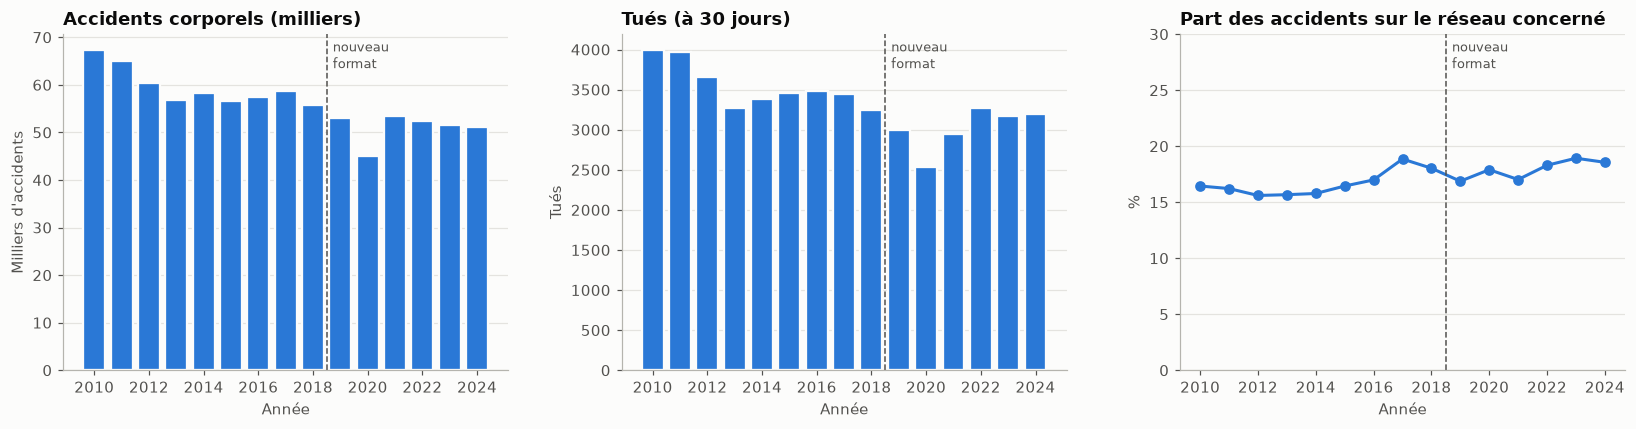

In [6]:
controle = ind.tableau_controle_annuel(accidents)
display(controle.round(3))
gr.tracer_description_annuelle(controle);

> **À rédiger.**

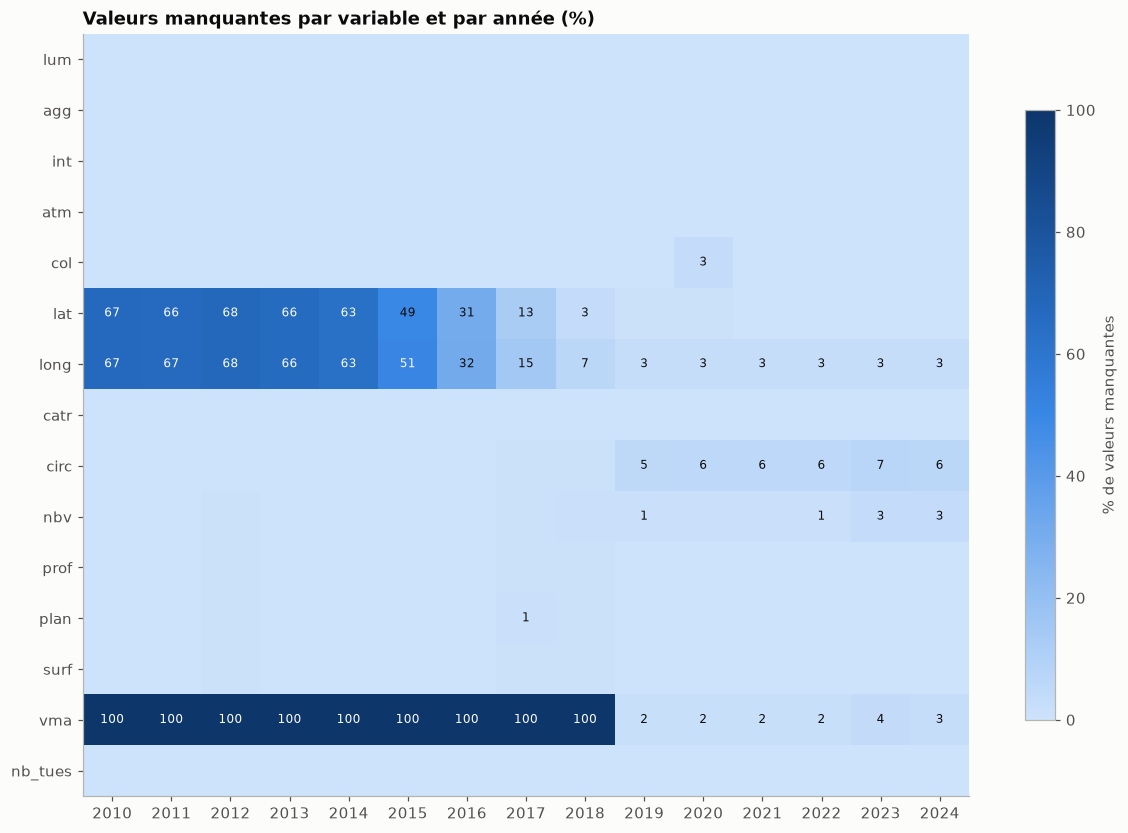

In [7]:
gr.heatmap_manquants(ind.valeurs_manquantes(accidents));

> **À rédiger.**

In [8]:
comparaison = ind.verifier_coherence_onisr(accidents, charger_departements_90())
display(comparaison[["tues_2019_calc", "tues_ha_2019_onisr", "tues_2022_calc", "tues_ha_2022_onisr"]].sum().to_frame("total"))

,total
tues_2019_calc,1790.0
tues_ha_2019_onisr,1944.0
tues_2022_calc,1934.0
tues_ha_2022_onisr,1934.0


> ✍️ **À rédiger.**

## 3. Le passage à 80 km/h en 2018 (Q1, H1)

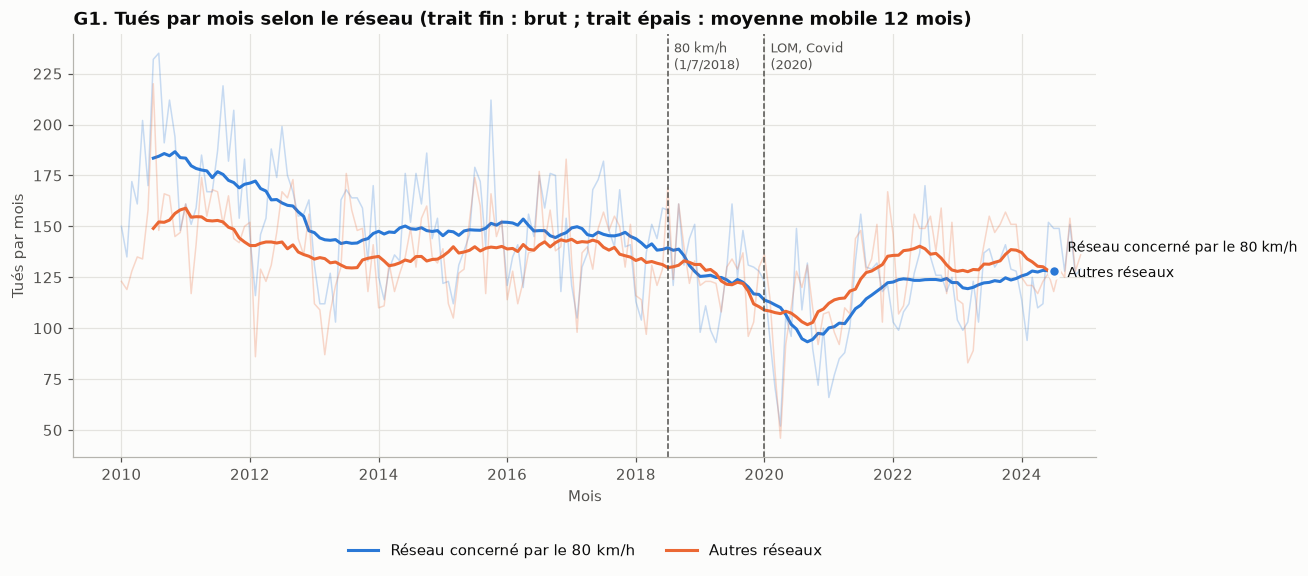

In [9]:
gr.tracer_mensuel_reseau(ind.tues_mensuels_par_reseau(accidents));

In [10]:
bilan = da.bilan_national(panel)
display(bilan[["tues_80", "tues_temoin", "indice_tues_80", "indice_tues_temoin", "indice_carburants_routiers_m3"]].round(1))

,tues_80,tues_temoin,indice_tues_80,indice_tues_temoin,indice_carburants_routiers_m3
annee,,,,,
2010,2202,1788,124.5,106.3,98.0
2011,2122,1835,120.0,109.1,96.7
2012,1938,1708,109.6,101.5,95.8
2013,1706,1557,96.5,92.6,94.9
2014,1786,1593,101.0,94.7,95.7
2015,1778,1680,100.5,99.9,96.7
2016,1775,1690,100.4,100.5,101.1
2017,1753,1677,99.1,99.7,102.2
2018,1674,1557,94.6,92.6,100.9


> **À rédiger.**

## 4. Le retour aux 90 km/h (Q2)

### 4.1 Qui a relevé, et quand ?

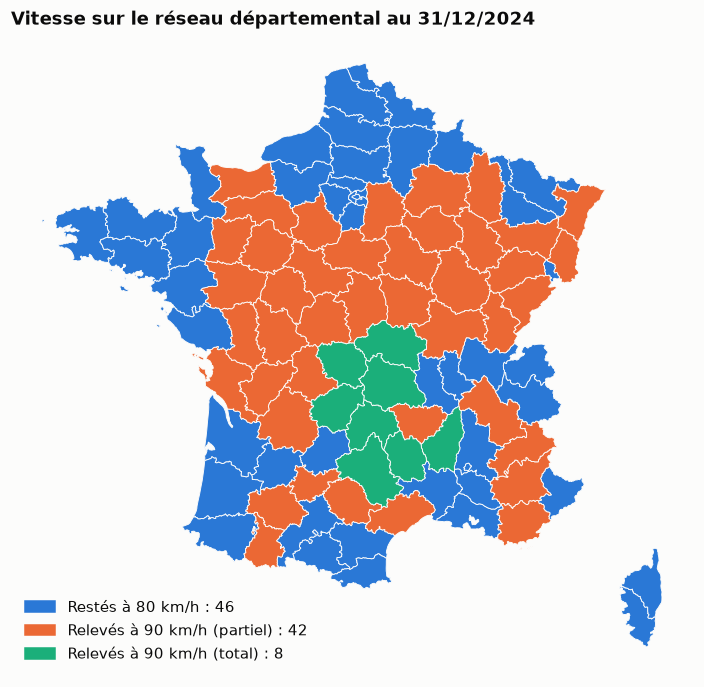

In [11]:
gr.carte_groupes(contours, groupes[["code_dep", "groupe"]]);

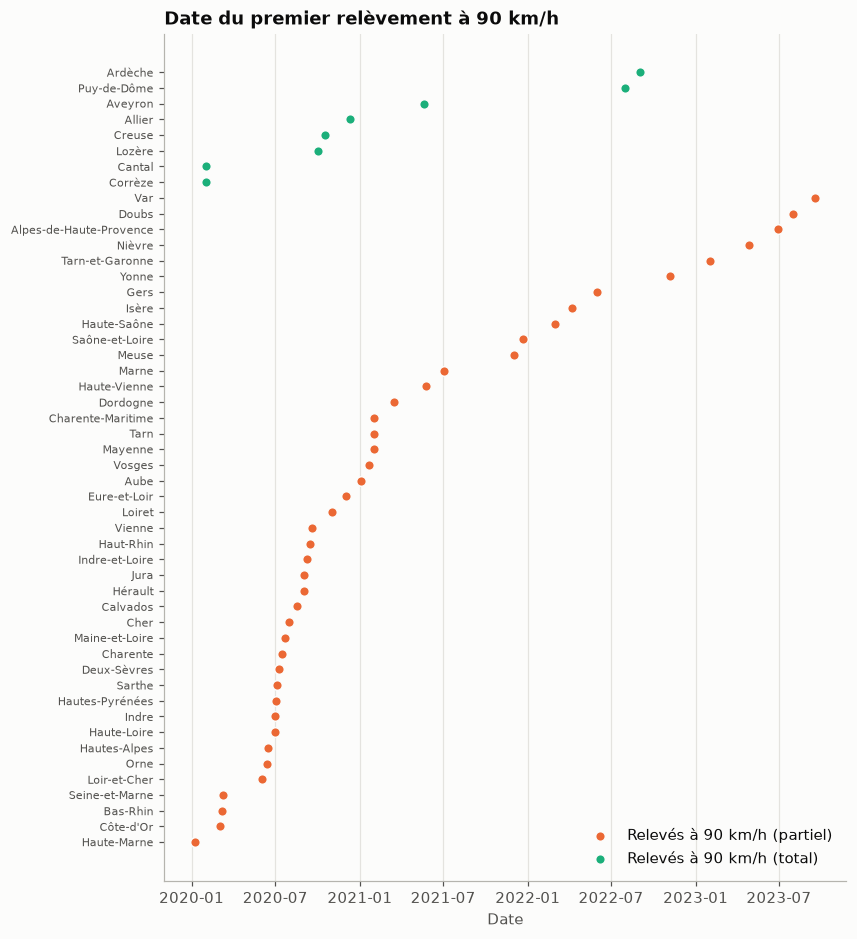

In [12]:
gr.tracer_calendrier(groupes.assign(date_releve=groupes["date_releve_eff"]));

rediger

### 4.2 Évolution comparée des groupes (graphique central)

Tués sur les routes départementales hors agglomération, par million d'habitants, en indice (moyenne 2015-2017 = 100). La bande colorée est un intervalle à 95 % (approximation de Poisson).

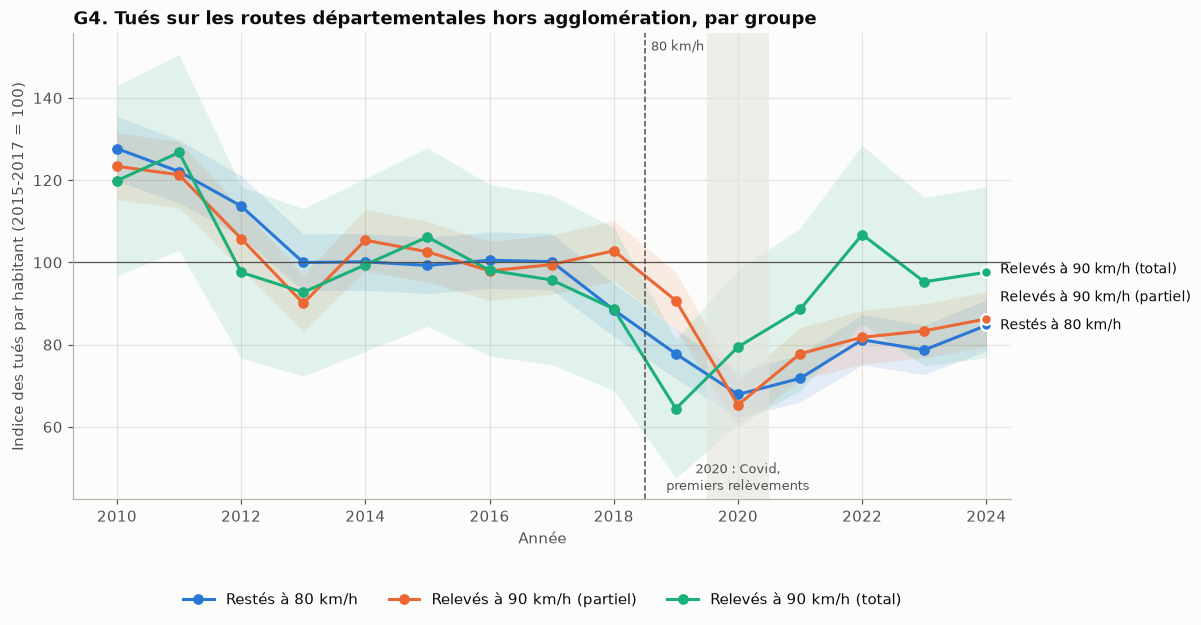

In [13]:
serie_g4 = ind.serie_groupes_ic(panel, variable=VARIABLE_Q2, par_habitant=True)
gr.tracer_series_groupes_ic(
    serie_g4,
    titre="G4. Tués sur les routes départementales hors agglomération, par groupe",
    ylabel="Indice des tués par habitant (2015-2017 = 100)",
);

rediger

### 4.3 Étude d'événement : chaque département aligné sur sa propre date

Pour chaque département relevé, l'année 0 est celle de son relèvement. On compare ses tués à ce qu'il aurait connu s'il avait suivi la même évolution que les départements restés à 80 km/h (base : moyenne des années −3 à −1). 100 = même évolution que les G80 ; au-dessus de 100 = évolution moins favorable.

groupe,G90_partiel,G90_total
annee_relative,,
-5,42,8
-4,42,8
-3,42,8
-2,42,8
-1,42,8
0,42,8
1,42,8
2,37,8
3,33,6


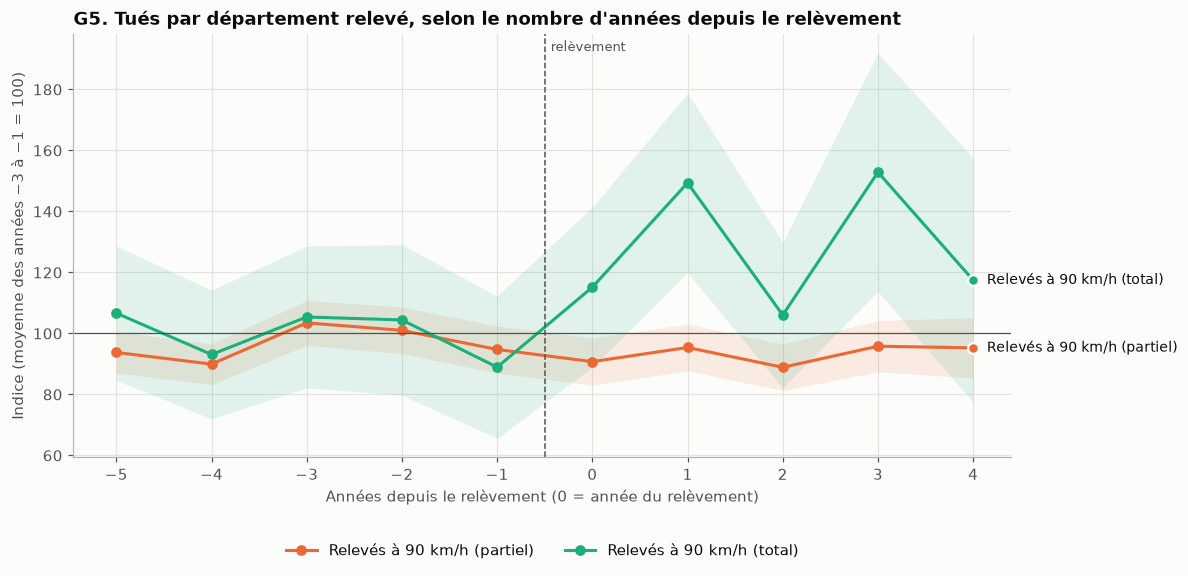

In [14]:
evenement = ind.etude_evenement(panel, variable=VARIABLE_Q2)
gr.tracer_evenement(evenement);
display(evenement.pivot(index="annee_relative", columns="groupe", values="nb_departements"))

rediger